# Data Understanding

This notebook focuses on understanding the structure, content, and basic characteristics of the California Housing Prices dataset, including initial exploratory data analysis (EDA), before data preparation and modeling.

## Objectives

* Load the dataset and inspect the first and last rows
* Understand the structure of the dataset and examine data types
* Review basic statistical information
* Identify missing values and duplicate records
* Analyze numerical and categorical feature distributions
* Detect potential outliers and data quality issues
* Develop an initial understanding of the features and the target variable (`median_house_value`)
* Explore correlations between features and the target variable
* Investigate relationships between important features and house prices, including geographic patterns
* Identify potential issues, such as capped values, that may affect modeling
* Identify useful insights for the modeling stage



In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

### 1. Load Dataset

In [6]:
df = pd.read_csv("../data/housing.csv")

### 2. Initial Inspection

In [7]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [8]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


The first few rows show that the dataset contains numerical housing features, a categorical `ocean_proximity` feature, and the target variable `median_house_value`. No obvious data quality issues are visible from these rows.

### 3. Data Types and Structure

In [9]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.info()

Rows: 20640, Columns: 10
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


#### Initial Observations

The dataset contains 20,640 records and 10 columns.

The `total_bedrooms` column has only 20,433 non-null values, meaning that 207 districts have missing values for this feature. These missing values will need to be addressed during data preparation.

The `ocean_proximity` column is the only non-numerical feature and represents a categorical variable. Its category distribution is examined below using `value_counts()`.

### 4. Statistical Summary

In [10]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


The numerical features have considerably different ranges and scales. For example, `total_rooms` and `population` have much larger numerical values than `median_income`.

Several features have maximum values substantially higher than their 75th percentiles, suggesting potentially extreme values that should be investigated further.

In [11]:
# Categorical feature summary
df.describe(include='str')

,ocean_proximity
count,20640
unique,5
top,<1H OCEAN
freq,9136


The `ocean_proximity` feature contains 5 unique categories and has no missing values. The most frequent category is `<1H OCEAN`, appearing in 9,136 records.

### 5. Categorical Feature Analysis

In [12]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

The `ISLAND` category is extremely rare, with only five records.

Text(0, 0.5, 'Count')

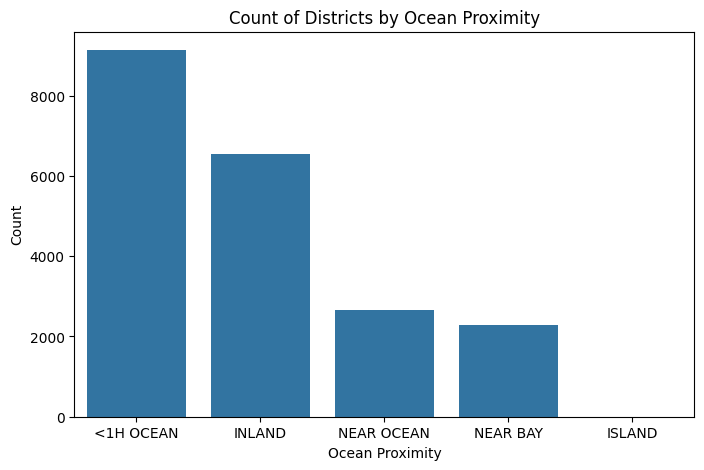

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="ocean_proximity",
    order=df["ocean_proximity"].value_counts().index
)

plt.title("Count of Districts by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Count")

### 6. Missing Values

In [14]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100
missing_df = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent.round(2)
})

missing_df[missing_df["missing_count"] > 0]

,missing_count,missing_percent
total_bedrooms,207,1.0


The `total_bedrooms` column contains missing values, accounting for approximately 1% of the total records.

### 7. Duplicate Records

In [15]:
df.duplicated().sum()

np.int64(0)

No duplicate records were identified in the dataset.

### 8. Unique Value Counts

In [16]:
df.nunique()

longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1923
population             3888
households             1815
median_income         12928
median_house_value     3842
ocean_proximity           5
dtype: int64

The number of unique values varies considerably across features. `housing_median_age` has only 52 unique values, while `median_income` has 12,928.

### 9. Quick Correlation Check with Target

In [17]:
correlation = df.corr(numeric_only=True)["median_house_value"].sort_values(ascending=False)
correlation

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

`median_income` shows the strongest positive correlation with `median_house_value` among the numerical features, making it a potentially important feature for prediction. A fuller correlation analysis, including a heatmap across all numerical features, is carried out in Section 14.

### 10. Histograms of Numerical Features

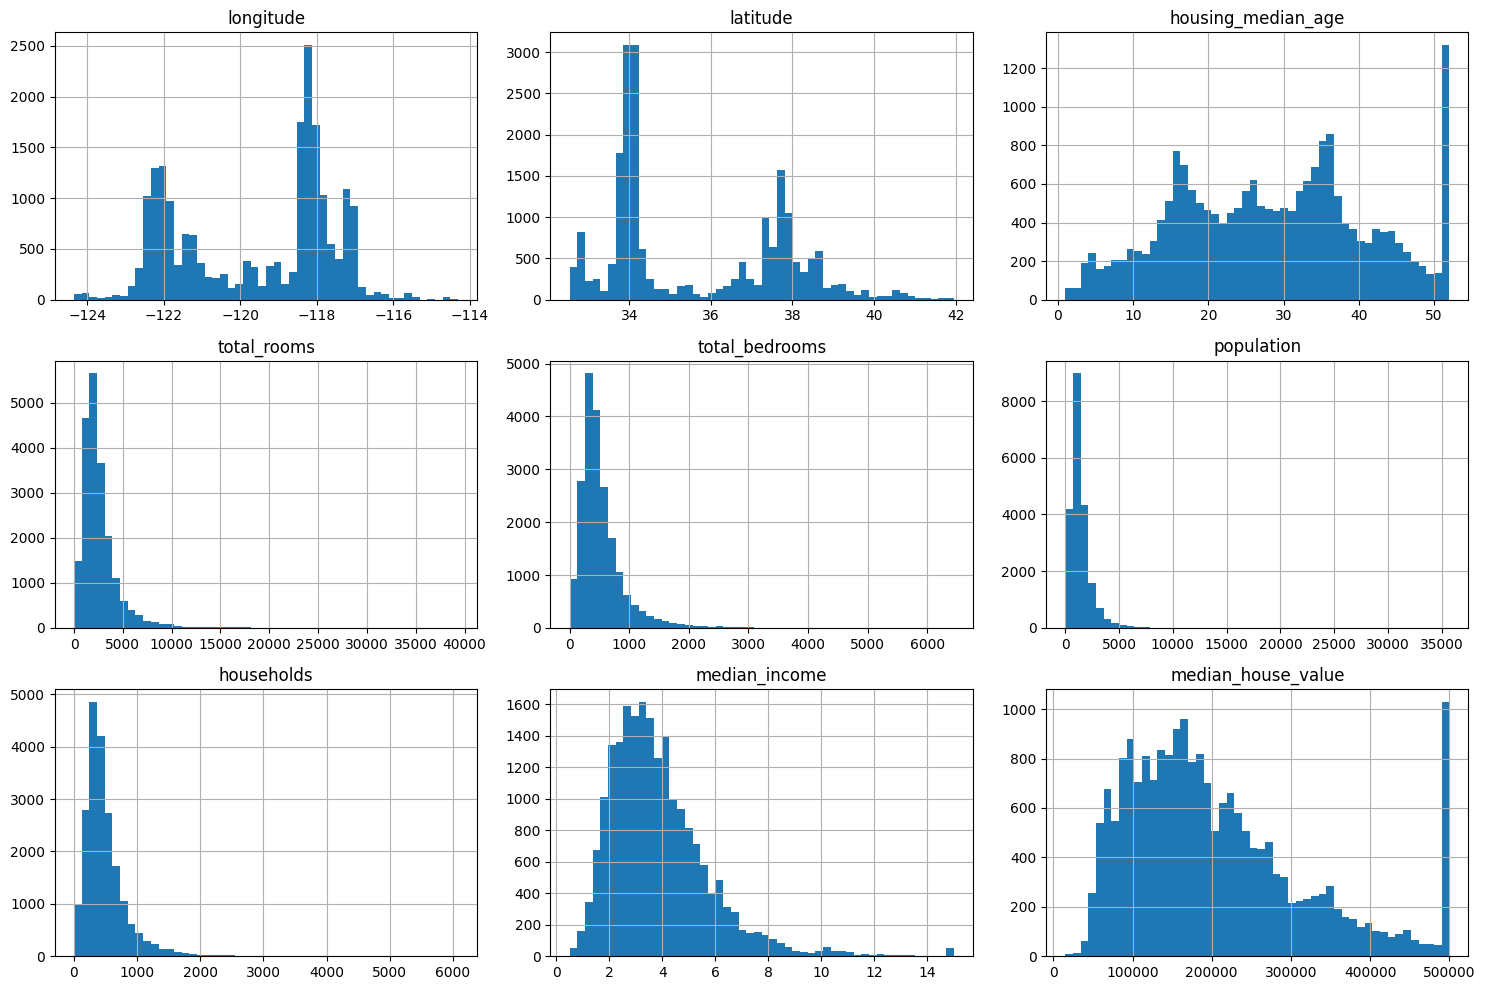

In [18]:
df.hist(bins=50, figsize=(15, 10))
plt.tight_layout()

#### Observations from Histograms

* Numerical features have very different scales, confirming the earlier observation from `describe()`. This should be considered during data preparation, depending on the models used.
* Several distributions are right-skewed, with longer tails toward higher values. Such skewness may affect some regression models, so transformations such as a log transform may be considered during data preparation.
* `median_income` is not expressed in raw US dollars. Its values are scaled and capped, ranging roughly from 0.5 to 15. This is a characteristic of the dataset and should be taken into account when interpreting the feature.
* `housing_median_age` and `median_house_value` show clear spikes at their maximum values, indicating that these variables are capped in the dataset. The cap on `median_house_value` is particularly important because it affects the target variable and may limit the model's ability to learn the true relationship for higher-priced homes. This issue should be considered during modeling and evaluation. The capping in `housing_median_age` is quantified below.

In [19]:
age_capped_value = df["housing_median_age"].max()
age_capped_count = (df["housing_median_age"] == age_capped_value).sum()
age_capped_pct = age_capped_count / len(df) * 100

print(f"Max housing_median_age: {age_capped_value}")
print(f"Districts at the cap: {age_capped_count} ({age_capped_pct:.2f}% of the dataset)")

Max housing_median_age: 52.0
Districts at the cap: 1273 (6.17% of the dataset)


**Observation:**

 1,273 districts (6.17% of the dataset) sit exactly at the maximum recorded age of 52 years, confirming that `housing_median_age` is capped in the same way as `median_house_value`, though affecting a larger share of records.

### 11. Target Variable Distribution

The target variable for this project is `median_house_value`.

We examine its distribution to understand the range and overall shape of house prices.

Text(0, 0.5, 'Frequency')

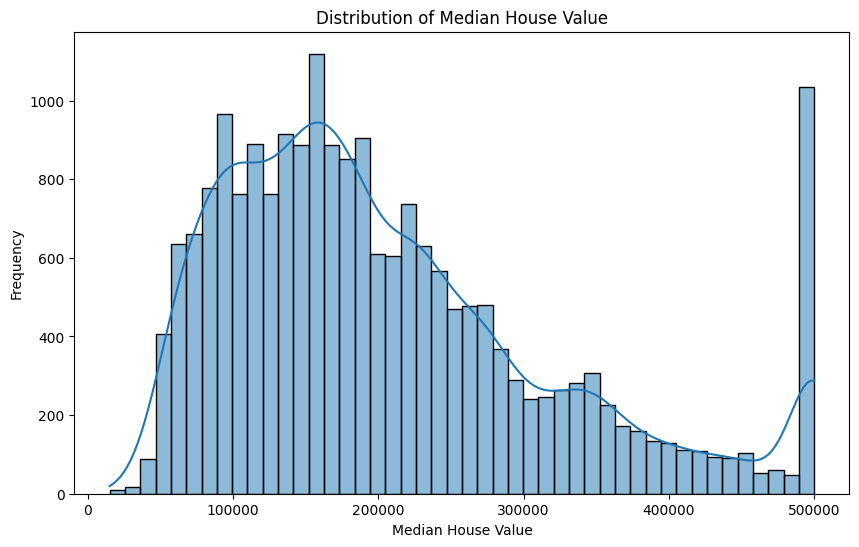

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="median_house_value",
    kde=True
)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

In [21]:
capped_value = df["median_house_value"].max()
capped_count = (df["median_house_value"] == capped_value).sum()
capped_pct = capped_count / len(df) * 100

print(f"Max median_house_value: {capped_value}")
print(f"Districts at the cap: {capped_count} ({capped_pct:.2f}% of the dataset)")

Max median_house_value: 500001.0
Districts at the cap: 965 (4.68% of the dataset)


**Observation:** 

The target distribution is right-skewed and shows a clear spike at the maximum value of $500,001. A total of 965 districts (4.68% of the dataset) are recorded at this value, indicating a capping artifact rather than a natural outlier. Because this affects the target variable, the ceiling effect should be considered during modeling and evaluation.

### 12. Outlier Detection

Boxplots are used to identify potential outliers in numerical features.

An outlier is not necessarily an incorrect observation. Potential outliers should be investigated before deciding whether they should be removed or transformed.

**Note:** the numerical features here have very different scales (e.g. `population` can be in the tens of thousands while `housing_median_age` tops out around 50), so plotting them on one shared axis makes most boxes unreadable. We plot each feature in its own subplot instead.

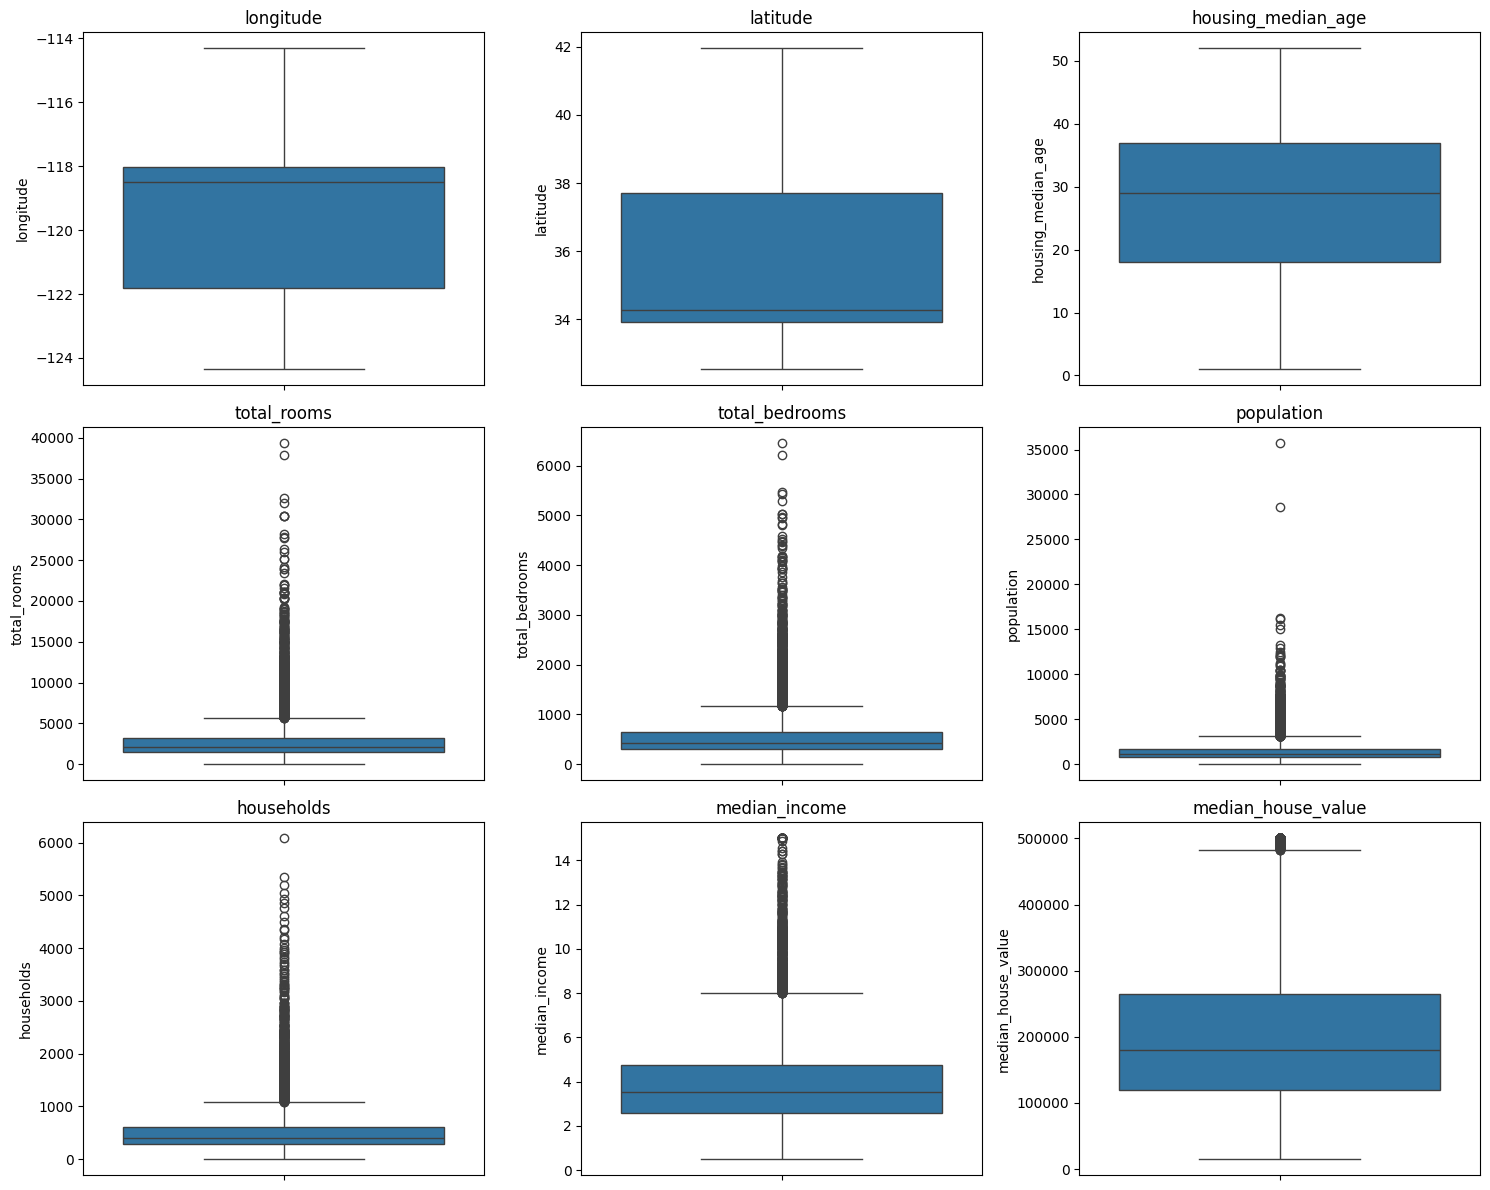

In [22]:
numerical_features = df.select_dtypes(include=[np.number]).columns.tolist()

n_cols = 3
n_rows = int(np.ceil(len(numerical_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(data=df, y=col, ax=axes[i])
    axes[i].set_title(col)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()

In [23]:
outlier_summary = {}

for col in numerical_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_pct = outlier_count / len(df) * 100
    outlier_summary[col] = {"count": outlier_count, "percent": round(outlier_pct, 2)}

pd.DataFrame(outlier_summary).T.sort_values("percent", ascending=False)

,count,percent
total_rooms,1287.0,6.24
total_bedrooms,1271.0,6.16
households,1220.0,5.91
population,1196.0,5.79
median_house_value,1071.0,5.19
median_income,681.0,3.30
longitude,0.0,0.00
latitude,0.0,0.00
housing_median_age,0.0,0.00


#### Observations from Boxplots

* Several numerical features show values beyond the upper whisker of their boxplots, particularly `total_rooms`, `total_bedrooms`, `population`, `households`, and `median_income`.
* Using the standard IQR rule (1.5×IQR beyond Q1/Q3), `total_rooms` has the highest share of flagged outliers (6.24%), followed closely by `total_bedrooms` (6.16%), `households` (5.91%), `population` (5.79%), and `median_house_value` (5.19%). `median_income` shows a notably lower share (3.30%), while `longitude`, `latitude`, and `housing_median_age` have none.
* These values are potential outliers based on the IQR rule, but they may represent valid observations rather than errors and should not be removed automatically.
* `median_house_value` shows values concentrated near its upper limit, consistent with the capping issue identified in the previous section. This likely explains most of its 5.19% IQR-flagged share.

### 13. Geographic Distribution

The geographic distribution of housing prices is explored using `latitude` and `longitude`, with points colored by `median_house_value` and sized by `population`. This helps identify geographic patterns and regional differences in housing prices.

Text(0, 0.5, 'Latitude')

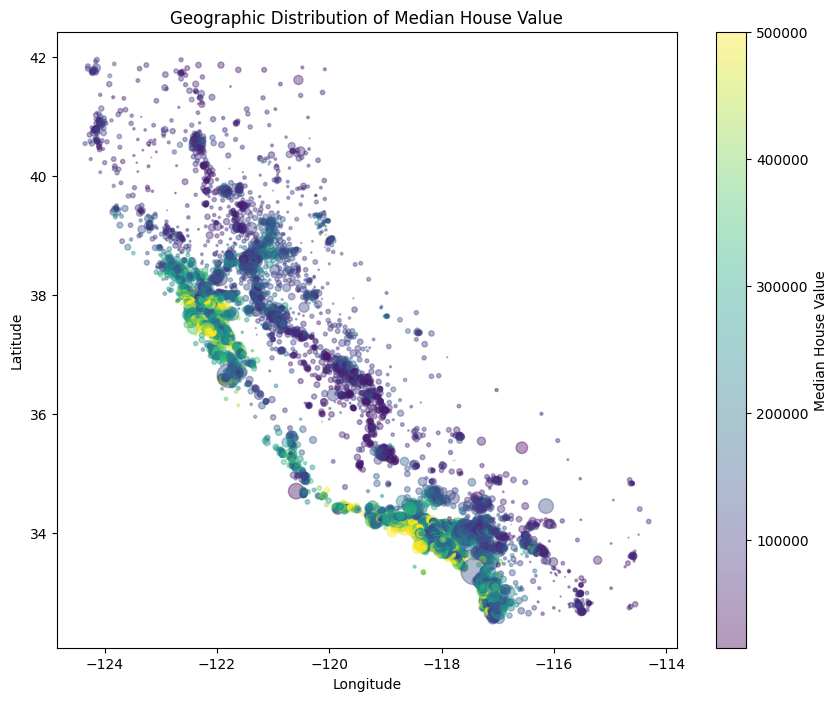

In [24]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["median_house_value"],
    cmap="viridis",
    s=df["population"] / 100,
    alpha=0.4
)

plt.colorbar(scatter, label="Median House Value")
plt.title("Geographic Distribution of Median House Value")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

#### Observations

* The plot shows clear geographic patterns in housing prices, with higher-priced districts concentrated in specific coastal and urban regions.

* Inland areas generally contain more lower-priced districts, while higher-priced districts are more concentrated near the coast.

* Larger points, representing higher population, are mainly concentrated around major urban areas.

* The geographic clustering suggests that `latitude` and `longitude` may provide useful information for predicting `median_house_value`.

### 14. Correlation Analysis (Full Matrix)

We examine the linear correlation between numerical features.

Correlation can help identify relationships between features and the target variable.

Correlation does not imply causation.

In [25]:
correlation_matrix = df[numerical_features].corr()

correlation_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


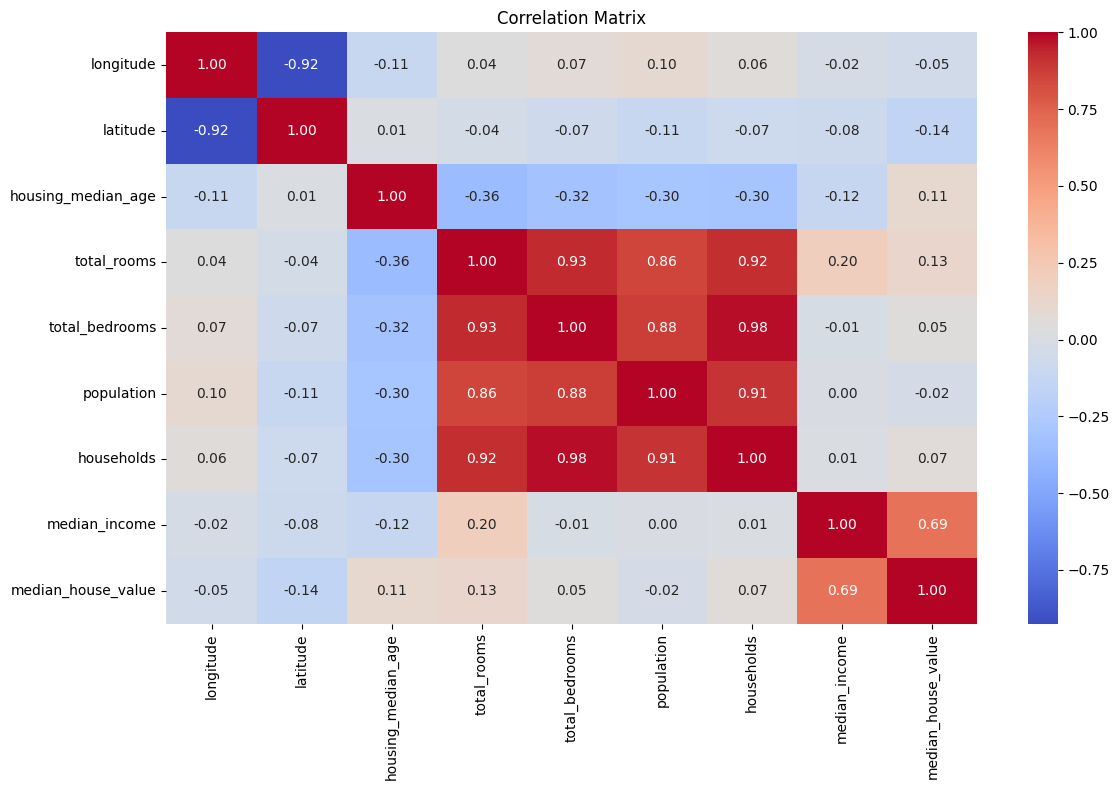

In [26]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.tight_layout()

#### Correlation with Target

We examine the correlation of each numerical feature with `median_house_value` to identify features that have stronger linear relationships with the target.

In [27]:
target_correlation = (
    correlation_matrix["median_house_value"]
    .sort_values(ascending=False)
)

target_correlation

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

#### Observations

* `median_income` has the strongest positive correlation with `median_house_value` (0.688), while `latitude` has the strongest negative correlation (-0.144).

* The size-related features (`total_rooms`, `total_bedrooms`, `population`, and `households`) have relatively weak linear correlations with the target individually.

* Several size-related features are highly correlated with each other. For example, `total_bedrooms` and `households` have a correlation of 0.980, while `total_rooms` is strongly correlated with `total_bedrooms` (0.930) and `households` (0.918). This indicates potential multicollinearity among these features.

* `longitude` and `latitude` also have a strong negative correlation (-0.925), reflecting the geographic structure of the dataset.

### 15. Feature vs Target Analysis

We visualize the relationship between selected features and the target variable.

This helps us understand whether the relationships appear linear, nonlinear, weak, or strong.

Text(0, 0.5, 'Median House Value')

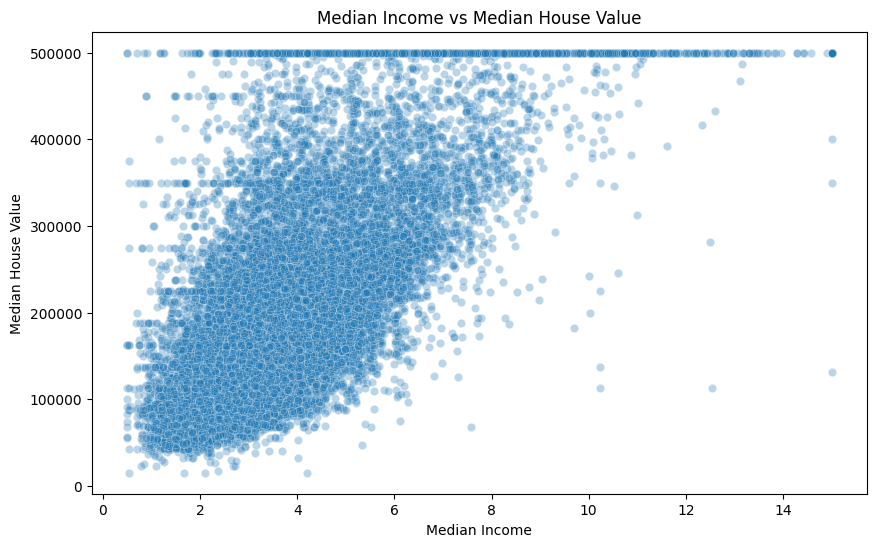

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

Text(0, 0.5, 'Median House Value')

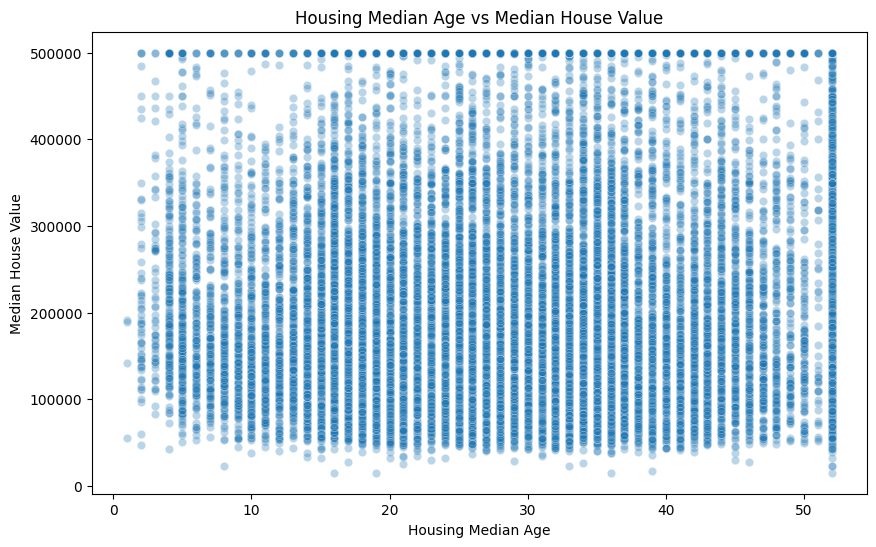

In [29]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="housing_median_age",
    y="median_house_value",
    alpha=0.3
)

plt.title("Housing Median Age vs Median House Value")
plt.xlabel("Housing Median Age")
plt.ylabel("Median House Value")

Text(0, 0.5, 'Median House Value')

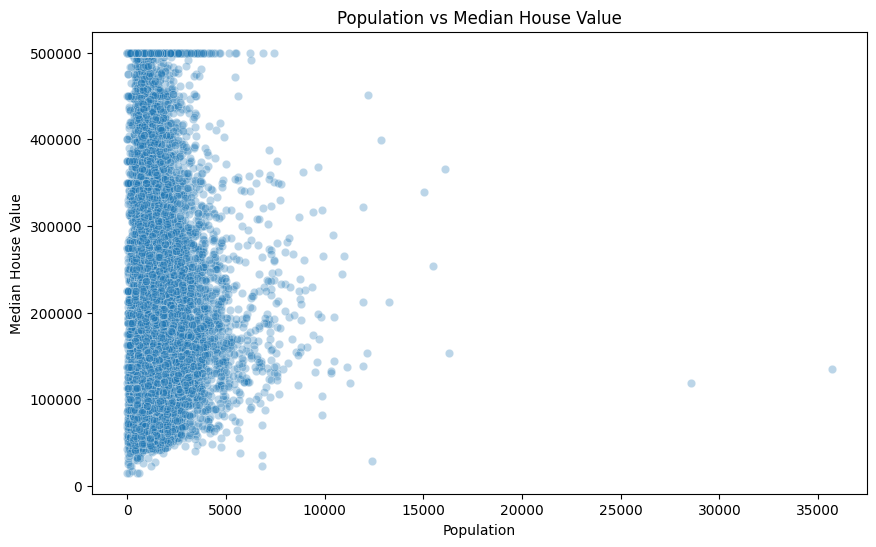

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="population",
    y="median_house_value",
    alpha=0.3
)

plt.title("Population vs Median House Value")
plt.xlabel("Population")
plt.ylabel("Median House Value")

We also look at `median_house_value` broken down by `ocean_proximity`, since it's the one feature not captured by the correlation matrix above.

Text(0, 0.5, 'Median House Value')

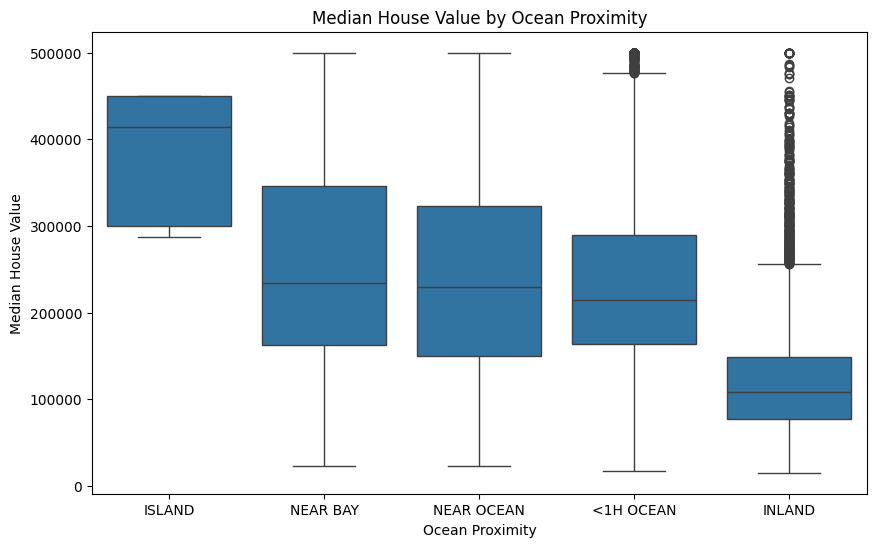

In [31]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value",
    order=df.groupby("ocean_proximity")["median_house_value"].median().sort_values(ascending=False).index
)

plt.title("Median House Value by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value")

#### Observations

* `median_income` shows the clearest positive relationship with `median_house_value` among the three scatterplots, consistent with its strong correlation coefficient (0.688). The spread of values also widens as income increases, forming a fan or cone-shaped pattern that suggests the variance in house prices is not constant across the income range.

* The `median_house_value` cap at $500,001 is visible as a dense horizontal band at the top of all three scatterplots, which confirms that the capping is a property of the target itself. The band spans the whole x-range, but it is not evenly spread: Section 16 shows that capped districts are concentrated among high-income and coastal districts. Other horizontal bands appear at round values such as $350,000 and $450,000. Section 16 shows that these belong to a general pattern of rounded prices and are not additional caps.

* `housing_median_age` shows no clear linear or nonlinear trend with `median_house_value`. Districts of every age contain both low and high median values, consistent with its weak correlation coefficient (0.106). The vertical striping reflects the fact that age is recorded in whole years.

* `population` shows a weak relationship with `median_house_value`. The vast majority of districts are concentrated at low to moderate population levels, while a handful of districts with very high populations, above 25,000, do not correspond to higher house values. These extreme points are worth revisiting alongside the outlier analysis in Section 12.

* `ocean_proximity` shows a clear ordering in median house values. `ISLAND` has the highest median value, although it is represented by very few districts, so this estimate should be interpreted cautiously. `INLAND` has the lowest median and a visibly narrower price range. `NEAR BAY`, `NEAR OCEAN`, and `<1H OCEAN` show broadly overlapping distributions. Capped districts are concentrated in `<1H OCEAN`, `NEAR OCEAN`, and `NEAR BAY` and are rare in `INLAND` (see Section 16).

### 16. Capped and Rounded Values in More Detail

Section 11 showed that 4.68% of districts sit at the target cap of $500,001. Here we check **where** those districts are, because a cap that is spread evenly is a different modeling problem from a cap that is concentrated in particular regions or income levels. We also look at the most frequent target values and at the cap in `median_income`.

In [32]:
df["is_capped"] = df["median_house_value"] == df["median_house_value"].max()

# Share of capped districts by income quintile
income_quintile = pd.qcut(df["median_income"], 5)
cap_by_income = df.groupby(income_quintile, observed=True)["is_capped"].agg(
    capped_count="sum", capped_percent="mean"
)
cap_by_income["capped_percent"] = (cap_by_income["capped_percent"] * 100).round(1)
cap_by_income

,capped_count,capped_percent
median_income,,
"(0.499, 2.352]",20,0.5
"(2.352, 3.141]",26,0.6
"(3.141, 3.967]",60,1.5
"(3.967, 5.11]",120,2.9
"(5.11, 15.0]",739,17.9


In [33]:
# Share of capped districts by ocean proximity
cap_by_ocean = df.groupby("ocean_proximity")["is_capped"].agg(
    capped_count="sum", capped_percent="mean"
)
cap_by_ocean["capped_percent"] = (cap_by_ocean["capped_percent"] * 100).round(1)
cap_by_ocean

,capped_count,capped_percent
ocean_proximity,,
<1H OCEAN,532,5.8
INLAND,27,0.4
ISLAND,0,0.0
NEAR BAY,194,8.5
NEAR OCEAN,212,8.0


In [34]:
print("Median income of capped districts:    ", round(df.loc[df["is_capped"], "median_income"].median(), 2))
print("Median income of non-capped districts:", round(df.loc[~df["is_capped"], "median_income"].median(), 2))
print()

# Most frequent target values
print(df["median_house_value"].value_counts().head(10))
print()
print("Districts at 350,000:", (df["median_house_value"] == 350000).sum())
print("Districts at 450,000:", (df["median_house_value"] == 450000).sum())
print()

# Cap in median_income
income_max = df["median_income"].max()
print(f"Districts at the median_income maximum ({income_max}):", (df["median_income"] == income_max).sum())

Median income of capped districts:     7.72
Median income of non-capped districts: 3.45

median_house_value
500001.0    965
137500.0    122
162500.0    117
112500.0    103
187500.0     93
225000.0     92
350000.0     79
87500.0      78
275000.0     65
150000.0     64
Name: count, dtype: int64

Districts at 350,000: 79
Districts at 450,000: 37

Districts at the median_income maximum (15.0001): 49


#### Observations

* Capped districts are strongly concentrated among high-income districts. In the four lower income quintiles, only 0.5% to 2.9% of districts are capped, while in the top quintile 17.9% are (739 of the 965 capped districts). The median income of capped districts is 7.72, compared with 3.45 for the others.
* By location, capped districts are most common in `NEAR BAY` (8.5%), `NEAR OCEAN` (8.0%), and `<1H OCEAN` (5.8%). Only 27 `INLAND` districts (0.4%) are capped, and `ISLAND` has none.
* The cap therefore mostly hides the true prices of the most expensive districts, not of districts across the whole range. A model trained on this data cannot learn how far prices rise above $500,001, so its predictions for the highest-priced districts should be interpreted with caution, and evaluation results should be read with this in mind.
* The most frequent target values are rounded values such as 137,500, 162,500, and 112,500. The values 350,000 (79 districts) and 450,000 (37 districts) are ordinary rounded values. Unlike $500,001 (965 districts), they do not form a dominant spike, so they are not additional caps.
* `median_income` also has a smaller cap: 49 districts sit at its maximum of 15.0001.

### 17. Per-Household Ratios: Plausibility Check

The summary below proposes per-household ratio features. Before relying on them, we check whether their values are plausible. These ratios are calculated on a copy of the data and are not added to `df`.

In [35]:
ratios = pd.DataFrame({
    "rooms_per_household": df["total_rooms"] / df["households"],
    "population_per_household": df["population"] / df["households"],
    "bedrooms_per_room": df["total_bedrooms"] / df["total_rooms"],
})

ratios.describe(percentiles=[0.01, 0.5, 0.99]).round(2)

,rooms_per_household,population_per_household,bedrooms_per_room
count,20640.00,20640.00,20433.00
mean,5.43,3.07,0.21
std,2.47,10.39,0.06
min,0.85,0.69,0.10
1%,2.58,1.54,0.12
50%,5.23,2.82,0.20
99%,10.36,5.39,0.41
max,141.91,1243.33,1.00


In [36]:
many_people = df["population"] / df["households"] > 10
many_rooms = df["total_rooms"] / df["households"] > 20
fewer_people_than_households = df["population"] / df["households"] < 1

print("Districts with more than 10 people per household:", many_people.sum())
print("Districts with more than 20 rooms per household:  ", many_rooms.sum())
print("Districts with fewer people than households:     ", fewer_people_than_households.sum())
print()
print("Median households, whole dataset:              ", df["households"].median())
print("Median households, >10 people per household:  ", df.loc[many_people, "households"].median())
print("Median households, >20 rooms per household:    ", df.loc[many_rooms, "households"].median())
print()
print(df.loc[many_people, "ocean_proximity"].value_counts())

Districts with more than 10 people per household: 37
Districts with more than 20 rooms per household:   69
Districts with fewer people than households:      3

Median households, whole dataset:               409.0
Median households, >10 people per household:   68.0
Median households, >20 rooms per household:     95.0

ocean_proximity
INLAND        20
NEAR OCEAN     7
NEAR BAY       5
<1H OCEAN      5
Name: count, dtype: int64


#### Observations

* Most ratios are plausible. Between the 1st and 99th percentiles, `rooms_per_household` ranges from 2.58 to 10.36 and `population_per_household` from 1.54 to 5.39.
* A small number of districts have extreme values: the maximum is 141.91 rooms per household and 1,243.33 people per household. In total, 37 districts have more than 10 people per household, 69 have more than 20 rooms per household, and 3 have fewer people than households (minimum 0.69).
* These districts are small. The median number of households is 68 for the high-occupancy group and 95 for the many-rooms group, compared with 409 in the whole dataset. Of the 37 high-occupancy districts, 20 are `INLAND`. Ratios calculated from small counts are unstable, and such districts may be special cases, although this notebook does not verify why they look different.
* `bedrooms_per_room` is less extreme, ranging from 0.10 to 1.00 with 99% of values below 0.41. Its 207 missing values come from the missing `total_bedrooms`.
* These extreme ratios should be reviewed when the ratio features are built in Data Preparation. Tree-based models are generally less sensitive to extreme values than linear models, which is worth remembering when comparing models.

### 18. Is the Missingness in `total_bedrooms` Random?

Section 6 found 207 missing values in `total_bedrooms`. Median imputation is reasonable if the missing districts look like the rest of the data. We compare the two groups.

In [37]:
missing_bedrooms = df["total_bedrooms"].isnull()

print("Ocean proximity share (%), missing vs not missing:")
print(
    (df.groupby(missing_bedrooms)["ocean_proximity"]
       .value_counts(normalize=True)
       .mul(100).round(1)
       .unstack(0)
       .rename(columns={True: "missing", False: "not missing"}))
)
print()
print(
    df.groupby(missing_bedrooms)[["median_house_value", "median_income", "households", "total_rooms"]]
      .median()
      .rename(index={True: "missing", False: "not missing"})
)

Ocean proximity share (%), missing vs not missing:
total_bedrooms   not missing  missing
ocean_proximity                      
<1H OCEAN               44.2     49.3
INLAND                  31.8     26.6
ISLAND                   0.0      NaN
NEAR BAY                11.1      9.7
NEAR OCEAN              12.9     14.5

                median_house_value  median_income  households  total_rooms
total_bedrooms                                                            
not missing               179700.0         3.5365       409.0       2127.0
missing                   175000.0         3.4115       427.0       2155.0


#### Observations

* The 207 districts with missing `total_bedrooms` look similar to the rest of the data: median house value 175,000 vs 179,700, median income 3.41 vs 3.54, median households 427 vs 409, and median `total_rooms` 2,155 vs 2,127.
* The ocean proximity mix differs somewhat (49.3% of the missing districts are `<1H OCEAN` vs 44.2% of the others, and 26.6% are `INLAND` vs 31.8%). These differences are modest, and this notebook does not test whether they are statistically meaningful.
* There is no strong sign that the missing values are linked to price or income, so median imputation is a reasonable choice, with the median learned from the training set only.

### 19. A Note on the Scope of This EDA

The exploration in this notebook uses the full dataset, so it includes the records that later become the test set. It is used only to understand the data and to decide what to do in data preparation. No statistic from this notebook (medians, means, scaling parameters, category encodings) is carried into the modeling pipeline. Imputation, scaling, and encoding are fitted on the training set only in the data preparation notebook, so the test set stays unseen for modeling and evaluation.

## Data Understanding Summary

### Dataset Overview

The dataset contains 20,640 records describing California housing districts, with 8 numerical features, 1 categorical feature (`ocean_proximity`), and the target variable `median_house_value`.

### Data Quality

* **Missing values:** `total_bedrooms` has 207 missing values (~1% of records) and will need imputation.
* **Duplicates:** None identified.
* **Capped values:** `median_house_value` is capped at $500,001, with 4.68% of districts (965 records) sitting exactly at this value. This represents a censoring artifact rather than a natural outlier. The cap appears at all income, age, and population levels (Section 15), confirming that it is a property of the target itself, but it is concentrated in high-income and coastal districts (Section 16), so it mostly affects the most expensive areas. `housing_median_age` shows a similar capping pattern at its maximum of 52 years, affecting 1,273 districts (6.17% of records), which is a larger share than the target's cap. Both require an explicit modeling decision.
* **Scaling:** `median_income` appears to already be scaled or capped, with values roughly between 0.5 and 15, rather than representing raw dollar amounts, suggesting prior preprocessing. Numerical features generally differ widely in scale, so scaling will be needed before modeling.
* **Outliers:** Using the IQR rule, `total_rooms` (6.24%), `total_bedrooms` (6.16%), `households` (5.91%), `population` (5.79%), and `median_house_value` (5.19%) show the highest shares of flagged records, while `longitude`, `latitude`, and `housing_median_age` show none. This includes a small number of districts with very high `population` (>25,000) that do not correspond to higher house values. These should be investigated rather than automatically removed.
* **Per-household ratios:** Most ratios are plausible, but a few districts have extreme values (up to 141.9 rooms and 1,243 people per household), mostly in districts with few households (Section 17). They should be reviewed when ratio features are built.
* **Missingness:** The 207 districts with missing `total_bedrooms` look similar to the others in price, income, and size, so median imputation is reasonable (Section 18).
* **Category imbalance:** `ocean_proximity` is unevenly distributed, with very few districts in the `ISLAND` category. Its high median house value should therefore be treated cautiously given the small sample size.

### Correlation & Feature Relationships

* `median_income` shows the strongest positive linear correlation with `median_house_value` (0.688) among all numerical features and the clearest visual relationship in the scatterplots. The spread of house values also widens as income increases, suggesting non-constant variance (heteroscedasticity) that may be worth considering during modeling and evaluation.
* Several size-related features are highly correlated with each other: `total_bedrooms` and `households` (0.980), `total_rooms` and `total_bedrooms` (0.930), and `total_rooms` and `households` (0.918). This indicates potential multicollinearity among raw count features. These same features (`total_rooms`, `total_bedrooms`, `households`, `population`) also show the highest IQR-flagged outlier shares above.
* Raw counts (`total_rooms`, `total_bedrooms`, `population`) show relatively weak correlation with the target on their own. Combined with their multicollinearity, this suggests that deriving per-household ratios, such as rooms per household and bedrooms per room, during Data Preparation may produce more informative and less redundant features.
* `housing_median_age` and `population` both show weak and unclear relationships with the target individually.
* `ocean_proximity` shows a clear association with price. Coastal categories trend higher than `INLAND`, which also has a visibly narrower price range.
* Geographic position (`latitude`/`longitude`) reveals clear regional price clusters, such as coastal areas and the Bay Area, which the correlation matrix alone does not capture. `longitude` and `latitude` are themselves strongly correlated (-0.925), reflecting California's geographic layout.
* Some feature-target relationships appear nonlinear, suggesting that linear models alone may not fully capture the structure in the data.

### Implications for Data Preparation

1. Impute missing values in `total_bedrooms`.
2. Decide how to handle the capped `median_house_value` and `housing_median_age` records, such as dropping them, using censor-aware modeling, or documenting the limitation as a caveat.
3. Review and decide on the treatment of potential outliers, including high-population districts and the size-related features flagged by the IQR rule. Also review districts with extreme per-household ratios (Section 17).
4. Encode `ocean_proximity`, for example, using one-hot encoding.
5. Construct per-household ratio features, such as `rooms_per_household`, `bedrooms_per_room`, and `population_per_household`, to address multicollinearity and improve on the weak standalone correlations of raw counts. Check these ratios for extreme values (Section 17) and consider how to limit their influence on models that are sensitive to outliers.
6. Apply appropriate preprocessing to numerical features, including scaling and log transformation for skewed features where appropriate.
7. Select relevant features for modeling while keeping multicollinearity among size-related features in mind, for example, through regularization or feature selection.
8. Split the dataset into training and testing sets.
9. Evaluate candidate regression models using MAE, MSE, and RMSE, while considering geographic structure, nonlinearity, and income-driven heteroscedasticity when choosing a model family and evaluation approach.